# Phase 3A Step 12 — Customer Segmentation, Revenue Exposure and Business Intelligence

## Customer Retention Intelligence System

This independent notebook turns the IBM Telco development split into descriptive business
intelligence. All segments are temporary, rule-based analytical views. They are not saved
features, clusters, calibrated individual risks, causal effects, or validated intervention
rules. No supervised model, hypothesis test, customer-level targeting list, or actual CLV
calculation is produced.

## 1. Independent setup and leakage-safe loading

The project root is detected from marker files and the configured input must equal
`data/processed/development.parquet`. The source checksum is recorded before analysis.
Previous notebooks are neither imported nor executed.

In [1]:
# ruff: noqa: E501
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    # Return the nearest parent containing the project markers.
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "params.yaml"
        ).is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
print(f"Configured random state preserved: {config['project']['random_state']}")
for package in ["pandas", "numpy", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
Configured random state preserved: 42
pandas: 2.3.3
numpy: 2.4.6
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 300)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update(
    {"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11}
)

source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
target_column = config["data"]["target_column"]
identifier_column = config["data"]["id_column"]
random_state = int(config["project"]["random_state"])
analysis_df = df.copy()
analysis_df["_churned"] = analysis_df[target_column].eq("Yes")
analysis_df["_churn_monthly_exposure"] = analysis_df["MonthlyCharges"].where(
    analysis_df["_churned"], 0.0
)
overall_churn_rate = analysis_df["_churned"].mean()
overall_monthly_charge_mean = analysis_df["MonthlyCharges"].mean()

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == {"No", "Yes"}
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Overall churn rate: {overall_churn_rate:.2%}")
print("Source SHA-256:", source_sha256_before)
display(df.head())

Development data: 5,634 rows × 21 columns
Overall churn rate: 26.54%
Source SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.1000,"5,475.9000",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.3500,212.3000,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.4500,137.1000,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.7500,"2,453.3000",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86.0000,"1,164.0500",No


# 2. Business intelligence fundamentals

- **Customer segmentation** divides a population into interpretable groups sharing business
  characteristics. **Attrition** is observed customer departure; **retention rate** is the
  retained share, $1-\text{churn rate}$.
- **Revenue exposure** is an amount associated with a population that may be commercially
  relevant. It is not automatically realized loss. **Customer value** is a current proxy
  such as charges; **customer lifetime value (CLV)** requires future margins, survival,
  acquisition/service costs, discounting, and often treatment response.
- **Churn rate** is churners divided by customers in a segment. **Churn volume** is the
  count of churners. A small segment can have a high rate but little volume; a large segment
  can dominate volume at a moderate rate.
- **Prioritization** balances risk, value, volume, cost, addressability, and expected
  incremental benefit. A descriptive group rate is not an individual's predicted churn
  probability.
- **Risk segmentation** compares historical group outcomes. **Descriptive segmentation**
  applies transparent business rules; **unsupervised clustering** learns similarity-based
  groups and requires separate stability and usefulness validation.

This static snapshot has no timestamps, verified currency, margin, contract revenue schedule,
retention treatment, cost, counterfactual outcome, or future billing. Therefore actual CLV,
realized revenue loss, and incremental retention benefit cannot be calculated reliably.

# 3. Business KPI dashboard

Monthly charges associated with customers labelled `Churn=Yes` are called
**churn-associated monthly-charge exposure**. They must not be labelled lost monthly
recurring revenue: currency, exact billing cadence beyond the field name, collection,
churn timing, and future revenue are not independently verified.

,value
Development customers,"5,634.0000"
Churned customers,"1,495.0000"
Retained customers,"4,139.0000"
Overall churn rate,0.2654
Overall retention rate,0.7346
Total monthly charges,"366,394.1000"
Churn-associated monthly-charge exposure,"111,329.1500"
Share of monthly charges associated with churn,0.3039
Average monthly charges per customer,65.0327
Average monthly charges — churned,74.4677


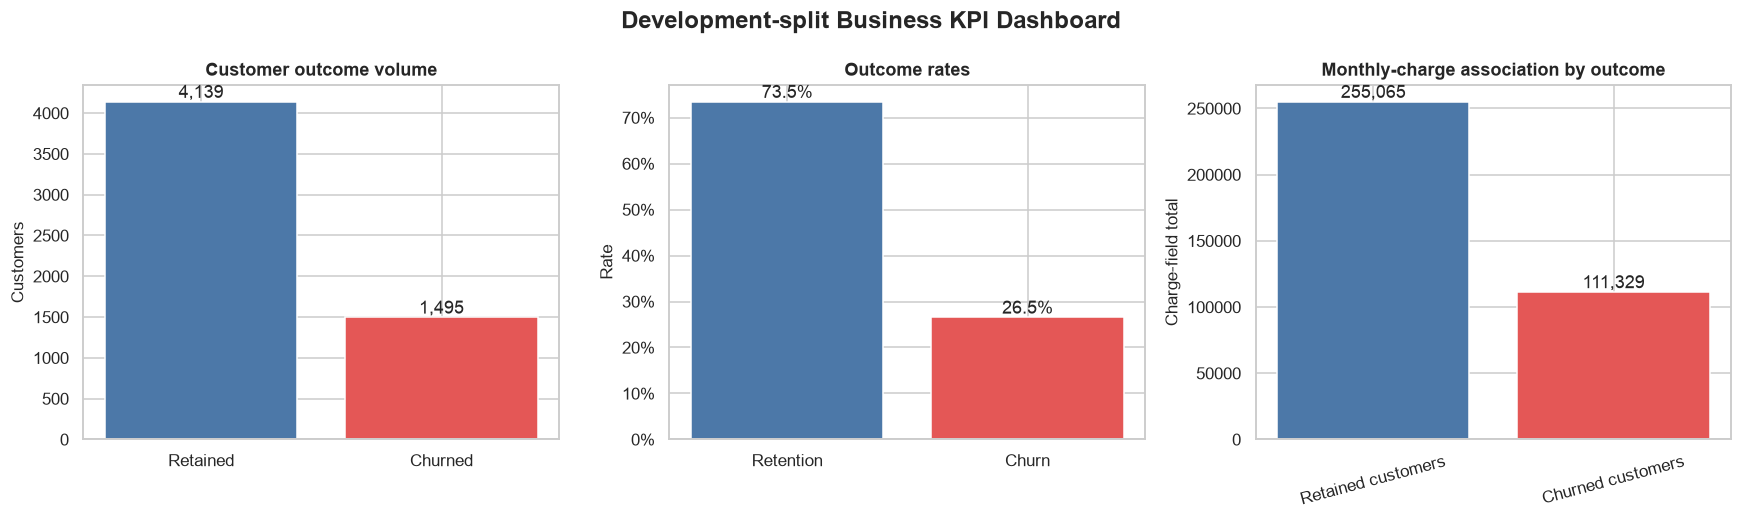

In [3]:
# ruff: noqa: E501
churned_mask = analysis_df["_churned"]
total_monthly_charges = analysis_df["MonthlyCharges"].sum()
churn_monthly_exposure = analysis_df.loc[churned_mask, "MonthlyCharges"].sum()
kpis = pd.Series(
    {
        "Development customers": len(analysis_df),
        "Churned customers": int(churned_mask.sum()),
        "Retained customers": int((~churned_mask).sum()),
        "Overall churn rate": overall_churn_rate,
        "Overall retention rate": 1 - overall_churn_rate,
        "Total monthly charges": total_monthly_charges,
        "Churn-associated monthly-charge exposure": churn_monthly_exposure,
        "Share of monthly charges associated with churn": churn_monthly_exposure
        / total_monthly_charges,
        "Average monthly charges per customer": analysis_df["MonthlyCharges"].mean(),
        "Average monthly charges — churned": analysis_df.loc[
            churned_mask, "MonthlyCharges"
        ].mean(),
        "Average monthly charges — retained": analysis_df.loc[
            ~churned_mask, "MonthlyCharges"
        ].mean(),
        "Median tenure (months)": analysis_df["tenure"].median(),
        "Total accumulated charges": analysis_df["TotalCharges"].sum(),
    },
    name="value",
)
display(kpis.to_frame())

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].bar(
    ["Retained", "Churned"],
    [(~churned_mask).sum(), churned_mask.sum()],
    color=["#4C78A8", "#E45756"],
)
axes[0].set(title="Customer outcome volume", ylabel="Customers")
axes[0].bar_label(axes[0].containers[0], labels=[f"{value:,.0f}" for value in [(~churned_mask).sum(), churned_mask.sum()]])
axes[1].bar(
    ["Retention", "Churn"],
    [1 - overall_churn_rate, overall_churn_rate],
    color=["#4C78A8", "#E45756"],
)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].set(title="Outcome rates", ylabel="Rate")
axes[1].bar_label(
    axes[1].containers[0],
    labels=[f"{1 - overall_churn_rate:.1%}", f"{overall_churn_rate:.1%}"],
)
axes[2].bar(
    ["Retained customers", "Churned customers"],
    [analysis_df.loc[~churned_mask, "MonthlyCharges"].sum(), churn_monthly_exposure],
    color=["#4C78A8", "#E45756"],
)
axes[2].set(title="Monthly-charge association by outcome", ylabel="Charge-field total")
axes[2].tick_params(axis="x", rotation=15)
axes[2].bar_label(axes[2].containers[0], labels=[f"{value:,.0f}" for value in [analysis_df.loc[~churned_mask, "MonthlyCharges"].sum(), churn_monthly_exposure]])
fig.suptitle("Development-split Business KPI Dashboard", fontsize=16, fontweight="bold")
fig.tight_layout()
plt.show()

**Observed KPI finding.** The development split contains 5,634 customers: 1,495 churned
and 4,139 retained, for 26.54% churn and 73.46% retention. Monthly charges total 366,394.10;
111,329.15 (30.39%) is associated with churned customers. Churned customers average 74.47
monthly-charge units versus 61.62 for retained customers. Median tenure is 29 months and
accumulated TotalCharges sum to 12,909,918.45. These are field totals, not verified currency,
profit, CLV, or realized loss.

# 4. Customer lifecycle segmentation

The temporary segments reuse Step 9 boundaries: 0–6 onboarding, 7–12 first year, 13–24
developing, 25–48 established, and 49–72 mature. For segment $s$,

$$\text{ChurnRate}_s=\frac{Churners_s}{Customers_s},\quad
\text{Lift}_s=\frac{\text{ChurnRate}_s}{\text{OverallChurnRate}}.$$

Lifecycle patterns can guide where to investigate onboarding, service, and commitment
experiences. They do not show that a particular retention action will work.

,customer_count,churned_count,mean_monthly_charges,median_monthly_charges,total_monthly_charge_exposure,churn_monthly_charge_exposure,retained_count,churn_rate,share_of_all_churners,churn_rate_lift
tenure_segment,,,,,,,,,,
0–6: Onboarding,1191,628,54.6265,55.0000,"65,060.1500","39,927.4000",563,0.5273,0.4201,1.9871
7–12: First year,565,204,59.1850,65.4500,"33,439.5000","15,412.4000",361,0.3611,0.1365,1.3607
13–24: Developing,810,234,61.7895,67.1000,"50,049.5000","18,335.1500",576,0.2889,0.1565,1.0887
25–48: Established,1272,261,66.4036,73.5250,"84,465.3500","22,317.5500",1011,0.2052,0.1746,0.7733
49–72: Mature,1796,168,74.2648,82.7750,"133,379.6000","15,336.6500",1628,0.0935,0.1124,0.3525


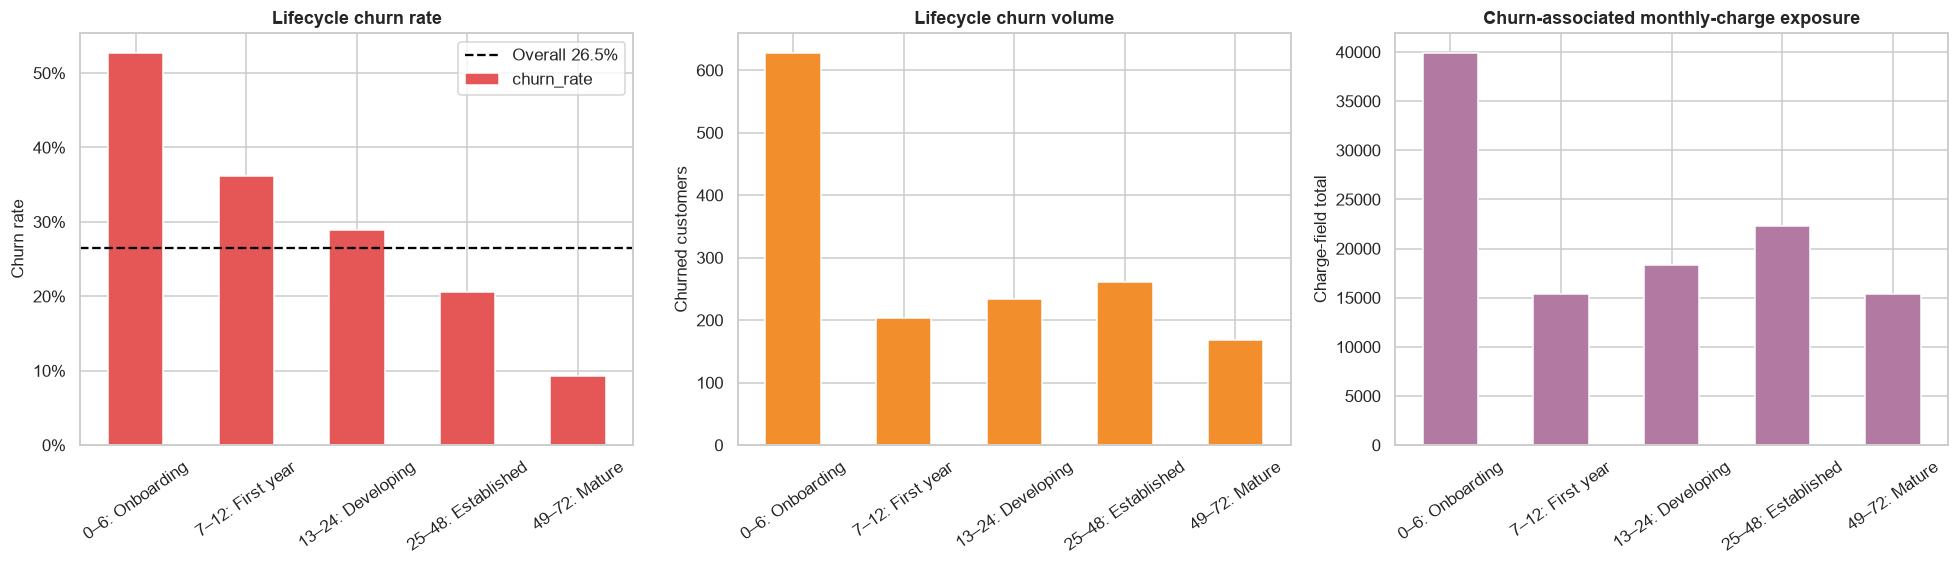

In [4]:
# ruff: noqa: E501
def segment_summary(data: pd.DataFrame, group_columns: str | list[str]) -> pd.DataFrame:
    # Build a reusable descriptive segment table.
    grouped = data.groupby(group_columns, observed=True)
    summary = grouped.agg(
        customer_count=(identifier_column, "size"),
        churned_count=("_churned", "sum"),
        mean_monthly_charges=("MonthlyCharges", "mean"),
        median_monthly_charges=("MonthlyCharges", "median"),
        total_monthly_charge_exposure=("MonthlyCharges", "sum"),
        churn_monthly_charge_exposure=("_churn_monthly_exposure", "sum"),
    )
    summary["retained_count"] = summary["customer_count"] - summary["churned_count"]
    summary["churn_rate"] = summary["churned_count"] / summary["customer_count"]
    summary["share_of_all_churners"] = (
        summary["churned_count"] / analysis_df["_churned"].sum()
    )
    summary["churn_rate_lift"] = summary["churn_rate"] / overall_churn_rate
    return summary


tenure_labels = [
    "0–6: Onboarding",
    "7–12: First year",
    "13–24: Developing",
    "25–48: Established",
    "49–72: Mature",
]
analysis_df["tenure_segment"] = pd.cut(
    analysis_df["tenure"],
    bins=[-0.001, 6, 12, 24, 48, 72],
    labels=tenure_labels,
    include_lowest=True,
    ordered=True,
)
lifecycle_summary = segment_summary(analysis_df, "tenure_segment")
display(lifecycle_summary)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.3))
lifecycle_summary["churn_rate"].plot.bar(ax=axes[0], color="#E45756")
axes[0].axhline(
    overall_churn_rate,
    color="black",
    linestyle="--",
    label=f"Overall {overall_churn_rate:.1%}",
)
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[0].set(title="Lifecycle churn rate", xlabel="", ylabel="Churn rate")
axes[0].legend()
lifecycle_summary["churned_count"].plot.bar(ax=axes[1], color="#F28E2B")
axes[1].set(title="Lifecycle churn volume", xlabel="", ylabel="Churned customers")
lifecycle_summary["churn_monthly_charge_exposure"].plot.bar(ax=axes[2], color="#B279A2")
axes[2].set(
    title="Churn-associated monthly-charge exposure",
    xlabel="",
    ylabel="Charge-field total",
)
for axis in axes:
    axis.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()

**Observed lifecycle finding.** Onboarding has 52.73% churn (lift 1.99), contributes 628
churners—42.01% of all churners—and 39,927.40 of exposure. Rates then decline through
36.11%, 28.89%, 20.52%, and 9.35% across later stages. Mature customers have the greatest
monthly-charge total (133,379.60) but the lowest observed churn rate. Lifecycle priority
must therefore separate high rate, high volume, and total customer value.

# 5. Customer value segmentation

MonthlyCharges quartiles are computed from development data only. Exact boundaries are
38.3125, 70.5250, and 89.9000. `pd.cut` uses intervals $(-\infty,Q_1]$,
$(Q_1,Q_2]$, $(Q_2,Q_3]$, and $(Q_3,\infty)$; ties equal to a boundary remain in the lower
interval. Monthly charges are a value proxy, not profit, margin, realized revenue, or CLV.

,observed_boundary
0.2500,38.3125
0.5000,70.5250
0.7500,89.9000


,customer_count,churned_count,mean_monthly_charges,median_monthly_charges,total_monthly_charge_exposure,churn_monthly_charge_exposure,retained_count,churn_rate,share_of_all_churners,churn_rate_lift
value_segment,,,,,,,,,,
Q1 Lower,1409,159,22.4052,20.3000,"31,568.9000","3,835.7500",1250,0.1128,0.1064,0.4253
Q2 Lower-middle,1408,357,56.3147,55.4500,"79,291.1000","20,032.1000",1051,0.2536,0.2388,0.9555
Q3 Upper-middle,1410,521,80.4618,80.2500,"113,451.1000","41,938.0000",889,0.3695,0.3485,1.3925
Q4 Higher,1407,458,100.9829,100.2000,"142,083.0000","45,523.3000",949,0.3255,0.3064,1.2267


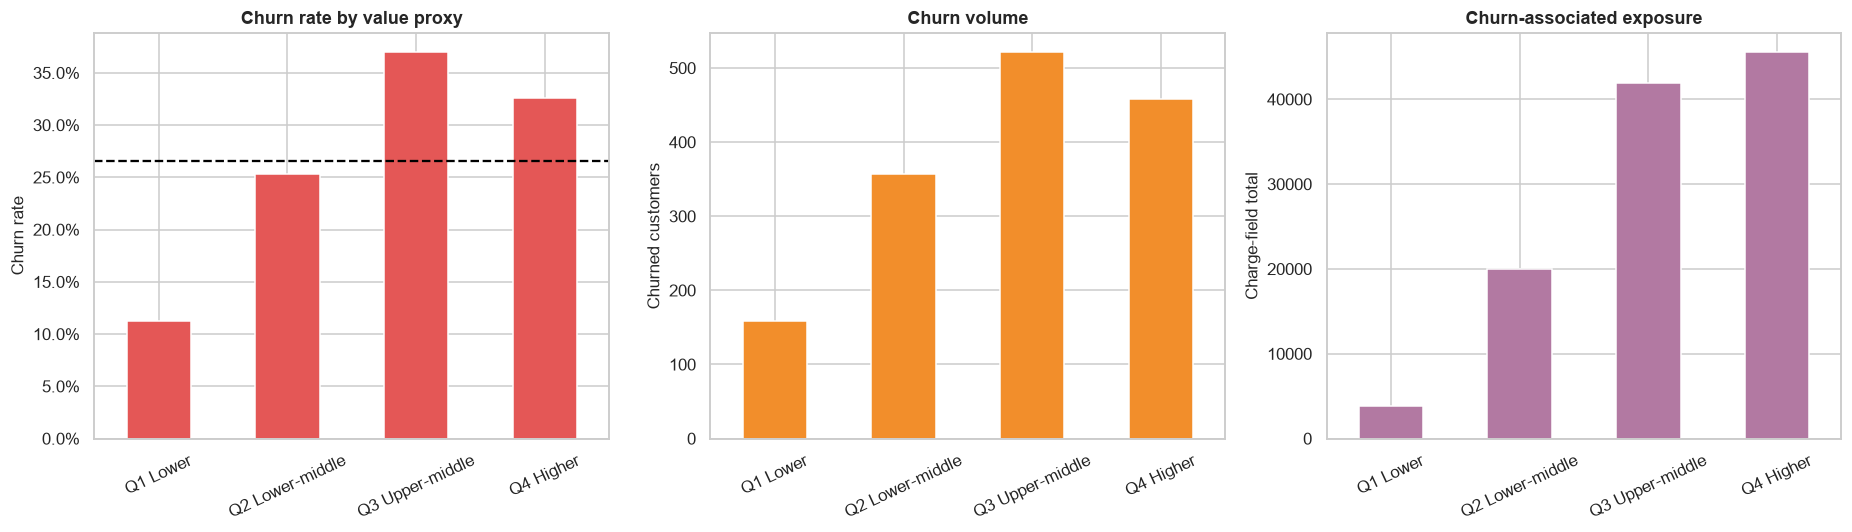

In [5]:
# ruff: noqa: E501
charge_quartiles = analysis_df["MonthlyCharges"].quantile([0.25, 0.50, 0.75])
value_labels = ["Q1 Lower", "Q2 Lower-middle", "Q3 Upper-middle", "Q4 Higher"]
analysis_df["value_segment"] = pd.cut(
    analysis_df["MonthlyCharges"],
    bins=[-np.inf, *charge_quartiles.tolist(), np.inf],
    labels=value_labels,
    include_lowest=True,
    ordered=True,
)
value_summary = segment_summary(analysis_df, "value_segment")
display(charge_quartiles.to_frame("observed_boundary"))
display(value_summary)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
value_summary["churn_rate"].plot.bar(ax=axes[0], color="#E45756")
axes[0].axhline(overall_churn_rate, color="black", linestyle="--")
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[0].set(title="Churn rate by value proxy", xlabel="", ylabel="Churn rate")
value_summary["churned_count"].plot.bar(ax=axes[1], color="#F28E2B")
axes[1].set(title="Churn volume", xlabel="", ylabel="Churned customers")
value_summary["churn_monthly_charge_exposure"].plot.bar(ax=axes[2], color="#B279A2")
axes[2].set(title="Churn-associated exposure", xlabel="", ylabel="Charge-field total")
for axis in axes:
    axis.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

**Observed value finding.** Q3 has the highest churn rate (36.95%) and volume (521), while
Q4 has a lower 32.55% rate but the greatest total monthly-charge exposure (142,083.00) and
churn-associated exposure (45,523.30). Q1 churn is 11.28%. Thus the highest current-charge
group has the greatest exposure but not the highest observed rate—an important rate-versus-
value distinction.

# 6. Customer engagement segmentation

The notebook-local service count has an explicit additive policy:

- one point for PhoneService;
- one incremental point for MultipleLines=`Yes`;
- one point for any InternetService;
- one point for each internet add-on explicitly equal to `Yes`.

Structural `No phone service` and `No internet service` states contribute zero and remain
distinct from eligible non-adoption. Parent services and add-ons are intentionally separate
dimensions: access is counted once, and each adopted add-on once. Bands are low 0–2,
moderate 3–5, and high 6–9. These are descriptive rules, not learned clusters or saved model
features.

In [6]:
# ruff: noqa: E501
internet_addons = [
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
]
analysis_df["service_count"] = (
    analysis_df["PhoneService"].eq("Yes").astype(int)
    + analysis_df["MultipleLines"].eq("Yes").astype(int)
    + analysis_df["InternetService"].ne("No").astype(int)
    + sum(analysis_df[feature].eq("Yes").astype(int) for feature in internet_addons)
)
analysis_df["adoption_band"] = pd.cut(
    analysis_df["service_count"],
    bins=[-0.1, 2, 5, 9],
    labels=["Low (0–2)", "Moderate (3–5)", "High (6–9)"],
    ordered=True,
)
analysis_df["support_security_profile"] = np.select(
    [
        analysis_df["InternetService"].eq("No"),
        analysis_df["OnlineSecurity"].eq("Yes") & analysis_df["TechSupport"].eq("Yes"),
        analysis_df["OnlineSecurity"].eq("Yes") & analysis_df["TechSupport"].ne("Yes"),
        analysis_df["OnlineSecurity"].ne("Yes") & analysis_df["TechSupport"].eq("Yes"),
    ],
    ["Not internet-eligible", "Security + support", "Security only", "Support only"],
    default="Neither security nor support",
)

adoption_summary = segment_summary(analysis_df, "adoption_band")
support_summary = segment_summary(analysis_df, "support_security_profile").sort_values(
    "churn_rate", ascending=False
)
internet_summary = segment_summary(analysis_df, "InternetService")
contract_summary = segment_summary(analysis_df, "Contract")
print("Service-count distribution")
display(
    analysis_df["service_count"]
    .value_counts()
    .sort_index()
    .rename("customers")
    .to_frame()
)
print("Adoption bands")
display(adoption_summary)
print("Security/support profiles")
display(support_summary)
print("Internet eligibility/type")
display(internet_summary)
print("Contract commitment")
display(contract_summary)

Service-count distribution


,customers
service_count,
1,1004
2,662
3,687
4,787
5,734
6,742
7,528
8,324
9,166


Adoption bands


,customer_count,churned_count,mean_monthly_charges,median_monthly_charges,total_monthly_charge_exposure,churn_monthly_charge_exposure,retained_count,churn_rate,share_of_all_churners,churn_rate_lift
adoption_band,,,,,,,,,,
Low (0–2),1666,316,29.0000,20.5500,"48,314.0500","13,734.8000",1350,0.1897,0.2114,0.7148
Moderate (3–5),2208,829,70.1536,74.7750,"154,899.1000","62,958.0000",1379,0.3755,0.5545,1.4149
High (6–9),1760,350,92.7164,97.9500,"163,180.9500","34,636.3500",1410,0.1989,0.2341,0.7494


Security/support profiles


,customer_count,churned_count,mean_monthly_charges,median_monthly_charges,total_monthly_charge_exposure,churn_monthly_charge_exposure,retained_count,churn_rate,share_of_all_churners,churn_rate_lift
support_security_profile,,,,,,,,,,
Neither security nor support,2050,1003,74.5574,78.7750,"152,842.6500","76,815.4500",1047,0.4893,0.6709,1.8438
Security only,736,160,75.2563,75.4000,"55,388.6500","12,492.2500",576,0.2174,0.1070,0.8193
Support only,766,164,80.0668,82.9000,"61,331.1500","13,520.5500",602,0.2141,0.1097,0.8068
Security + support,875,78,81.6460,81.2500,"71,440.2500","6,668.4500",797,0.0891,0.0522,0.3359
Not internet-eligible,1207,90,21.0368,20.1000,"25,391.4000","1,832.4500",1117,0.0746,0.0602,0.2810


Internet eligibility/type


,customer_count,churned_count,mean_monthly_charges,median_monthly_charges,total_monthly_charge_exposure,churn_monthly_charge_exposure,retained_count,churn_rate,share_of_all_churners,churn_rate_lift
InternetService,,,,,,,,,,
DSL,1934,368,58.3507,56.3500,"112,850.2500","18,172.3000",1566,0.1903,0.2462,0.7171
Fiber optic,2493,1037,91.5172,91.8500,"228,152.4500","91,324.4000",1456,0.4160,0.6936,1.5676
No,1207,90,21.0368,20.1000,"25,391.4000","1,832.4500",1117,0.0746,0.0602,0.2810


Contract commitment


,customer_count,churned_count,mean_monthly_charges,median_monthly_charges,total_monthly_charge_exposure,churn_monthly_charge_exposure,retained_count,churn_rate,share_of_all_churners,churn_rate_lift
Contract,,,,,,,,,,
Month-to-month,3095,1326,66.7551,73.7500,"206,607.1000","97,120.9000",1769,0.4284,0.8870,1.6146
One year,1178,130,64.7350,67.6000,"76,257.8000","10,904.9000",1048,0.1104,0.0870,0.4159
Two year,1361,39,61.3734,64.9000,"83,529.2000","3,303.3500",1322,0.0287,0.0261,0.1080


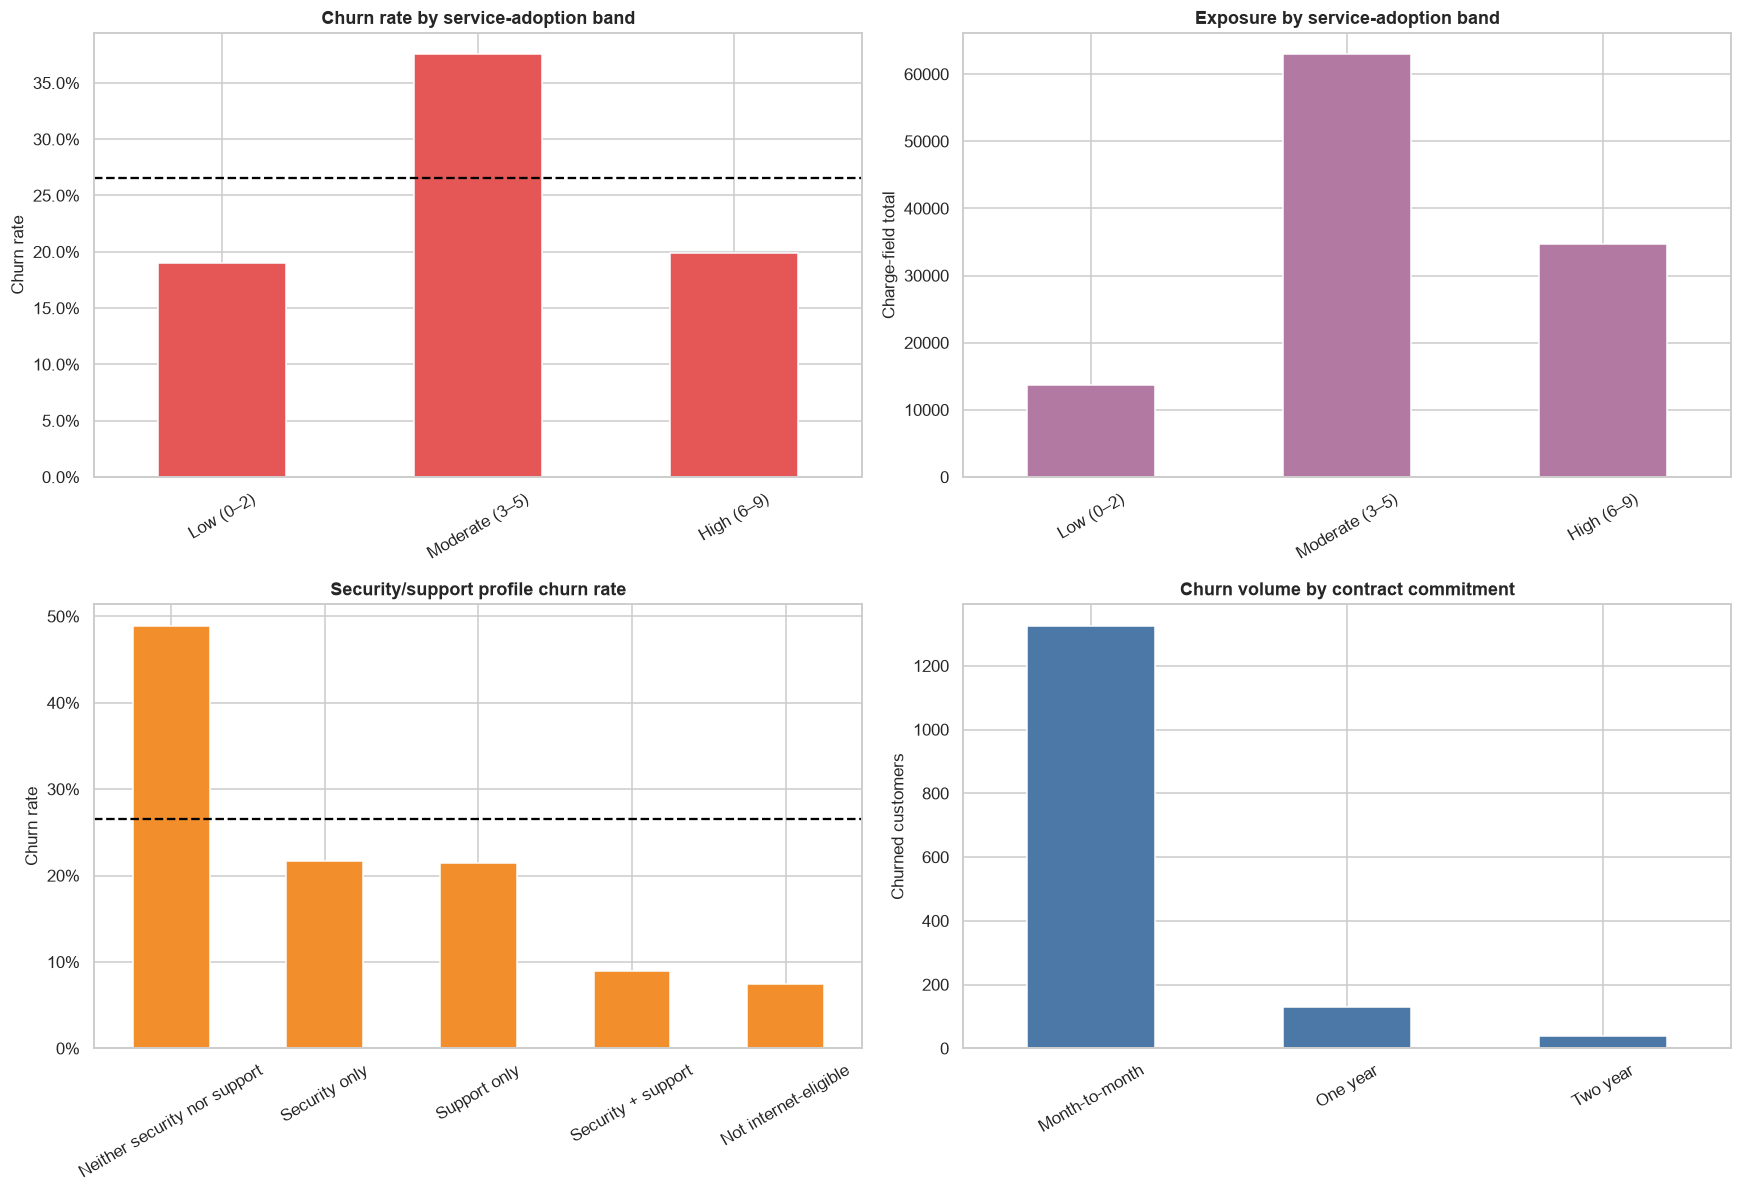

In [7]:
# ruff: noqa: E501
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
adoption_summary["churn_rate"].plot.bar(ax=axes[0, 0], color="#E45756")
axes[0, 0].axhline(overall_churn_rate, color="black", linestyle="--")
axes[0, 0].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[0, 0].set(
    title="Churn rate by service-adoption band", xlabel="", ylabel="Churn rate"
)
adoption_summary["churn_monthly_charge_exposure"].plot.bar(
    ax=axes[0, 1], color="#B279A2"
)
axes[0, 1].set(
    title="Exposure by service-adoption band", xlabel="", ylabel="Charge-field total"
)
support_summary["churn_rate"].plot.bar(ax=axes[1, 0], color="#F28E2B")
axes[1, 0].axhline(overall_churn_rate, color="black", linestyle="--")
axes[1, 0].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1, 0].set(
    title="Security/support profile churn rate", xlabel="", ylabel="Churn rate"
)
contract_summary["churned_count"].plot.bar(ax=axes[1, 1], color="#4C78A8")
axes[1, 1].set(
    title="Churn volume by contract commitment", xlabel="", ylabel="Churned customers"
)
for axis in axes.flat:
    axis.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

**Observed engagement finding.** Moderate adoption has the highest churn rate (37.55%),
829 churners (55.45% of all churners), and 62,958.00 exposure; high adoption falls to
19.89%, showing that service count is not a monotonic risk scale. Among internet subscribers,
lacking both security and support has 48.93% churn, 1,003 churners, and 76,815.45 exposure.
Fibre customers have 41.60% churn. Month-to-month contracts contribute 1,326 churners
(88.70%) and 97,120.90 exposure. These are overlapping views and must not be summed together.

# 7. Combined observed-risk and value segmentation

The matrix uses mutually exclusive **Contract × Lifecycle** groups. Group risk is “high”
when its observed churn rate is at least the development baseline (26.54%); value is “high”
when its mean MonthlyCharges is at least the development mean (65.03). These transparent
thresholds are exploratory, not optimized. Groups below 30 customers are labelled
insufficient-sample and excluded from quadrants.

Observed group rates summarize history. They are not calibrated individual probabilities,
and no customer is assigned a prospective risk category from their own Churn label.

,Contract,tenure_segment,customer_count,churned_count,mean_monthly_charges,median_monthly_charges,total_monthly_charge_exposure,churn_monthly_charge_exposure,retained_count,churn_rate,share_of_all_churners,churn_rate_lift,sample_sufficient,observed_risk_band,value_band,risk_value_quadrant
0,Month-to-month,0–6: Onboarding,1130,625,55.8926,55.7000,"63,158.6500","39,732.4500",505,0.5531,0.4181,2.0844,True,High observed risk,Low monthly-charge value,High observed risk / Low monthly-charge value
1,Month-to-month,7–12: First year,456,195,64.4753,72.9000,"29,400.7500","14,974.4000",261,0.4276,0.1304,1.6116,True,High observed risk,Low monthly-charge value,High observed risk / Low monthly-charge value
2,Month-to-month,13–24: Developing,584,219,69.4967,75.3750,"40,586.0500","17,333.8000",365,0.3750,0.1465,1.4132,True,High observed risk,High monthly-charge value,High observed risk / High monthly-charge value
3,Month-to-month,25–48: Established,653,217,76.6239,83.9000,"50,035.4000","18,776.8000",436,0.3323,0.1452,1.2523,True,High observed risk,High monthly-charge value,High observed risk / High monthly-charge value
4,Month-to-month,49–72: Mature,272,70,86.1259,93.2500,"23,426.2500","6,303.4500",202,0.2574,0.0468,0.9699,True,Low observed risk,High monthly-charge value,Low observed risk / High monthly-charge value
5,One year,0–6: Onboarding,36,3,27.9681,20.3500,"1,006.8500",194.9500,33,0.0833,0.0020,0.3140,True,Low observed risk,Low monthly-charge value,Low observed risk / Low monthly-charge value
6,One year,7–12: First year,78,9,40.6955,28.3250,"3,174.2500",438.0000,69,0.1154,0.0060,0.4348,True,Low observed risk,Low monthly-charge value,Low observed risk / Low monthly-charge value
7,One year,13–24: Developing,159,15,46.1903,45.9000,"7,344.2500","1,001.3500",144,0.0943,0.0100,0.3555,True,Low observed risk,Low monthly-charge value,Low observed risk / Low monthly-charge value
8,One year,25–48: Established,401,39,61.6469,63.7000,"24,720.4000","3,237.0500",362,0.0973,0.0261,0.3665,True,Low observed risk,Low monthly-charge value,Low observed risk / Low monthly-charge value
9,One year,49–72: Mature,504,64,79.3890,89.2250,"40,012.0500","6,033.5500",440,0.1270,0.0428,0.4785,True,Low observed risk,High monthly-charge value,Low observed risk / High monthly-charge value


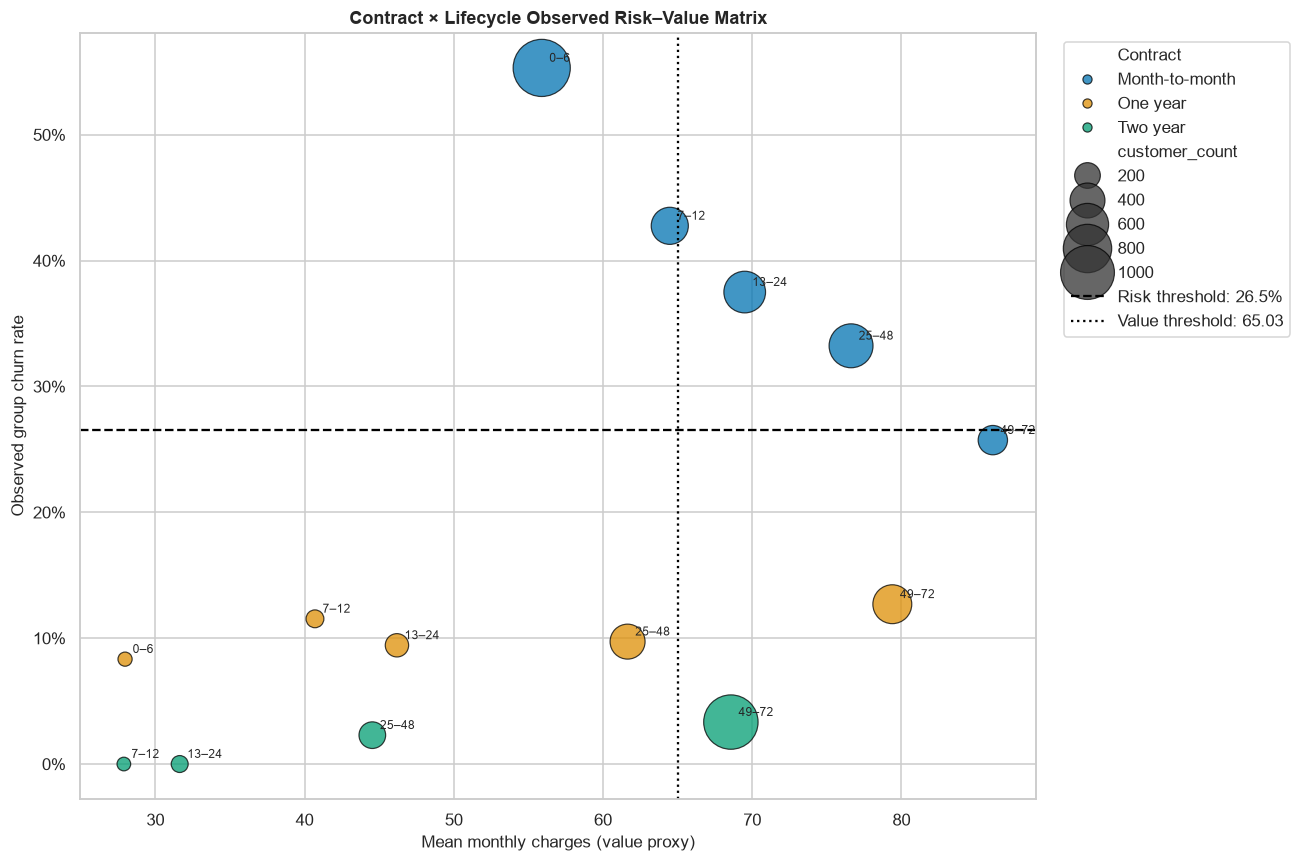

,segment_count,customers,churners,churn_monthly_exposure
risk_value_quadrant,,,,
High observed risk / High monthly-charge value,2,1237,436,"36,110.6000"
High observed risk / Low monthly-charge value,2,1586,820,"54,706.8500"
Insufficient sample (<30),1,25,0,0.0000
Low observed risk / High monthly-charge value,3,1796,168,"15,336.6500"
Low observed risk / Low monthly-charge value,7,990,71,"5,175.0500"


In [8]:
# ruff: noqa: E501
risk_value = segment_summary(analysis_df, ["Contract", "tenure_segment"]).reset_index()
risk_value["sample_sufficient"] = risk_value["customer_count"].ge(30)
risk_value["observed_risk_band"] = np.where(
    risk_value["churn_rate"].ge(overall_churn_rate),
    "High observed risk",
    "Low observed risk",
)
risk_value["value_band"] = np.where(
    risk_value["mean_monthly_charges"].ge(overall_monthly_charge_mean),
    "High monthly-charge value",
    "Low monthly-charge value",
)
risk_value["risk_value_quadrant"] = np.where(
    risk_value["sample_sufficient"],
    risk_value["observed_risk_band"] + " / " + risk_value["value_band"],
    "Insufficient sample (<30)",
)
display(risk_value)

plot_risk_value = risk_value[risk_value["sample_sufficient"]].copy()
fig, axis = plt.subplots(figsize=(12, 8))
sns.scatterplot(
    data=plot_risk_value,
    x="mean_monthly_charges",
    y="churn_rate",
    size="customer_count",
    hue="Contract",
    sizes=(80, 1400),
    alpha=0.75,
    edgecolor="black",
    ax=axis,
)
axis.axhline(
    overall_churn_rate,
    color="black",
    linestyle="--",
    label=f"Risk threshold: {overall_churn_rate:.1%}",
)
axis.axvline(
    overall_monthly_charge_mean,
    color="black",
    linestyle=":",
    label=f"Value threshold: {overall_monthly_charge_mean:.2f}",
)
for _, row in plot_risk_value.iterrows():
    axis.annotate(
        str(row["tenure_segment"]).split(":")[0],
        (row["mean_monthly_charges"], row["churn_rate"]),
        xytext=(5, 4),
        textcoords="offset points",
        fontsize=8,
    )
axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
axis.set(
    title="Contract × Lifecycle Observed Risk–Value Matrix",
    xlabel="Mean monthly charges (value proxy)",
    ylabel="Observed group churn rate",
)
axis.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

quadrant_summary = risk_value.groupby("risk_value_quadrant", observed=True).agg(
    segment_count=("risk_value_quadrant", "size"),
    customers=("customer_count", "sum"),
    churners=("churned_count", "sum"),
    churn_monthly_exposure=("churn_monthly_charge_exposure", "sum"),
)
display(quadrant_summary)

**Observed risk–value finding.** High-risk/high-value groups are month-to-month developing
and established customers: 1,237 customers, 436 churners, and 36,110.60 exposure. The two
high-risk/low-value month-to-month early groups contain 1,586 customers, 820 churners, and
54,706.85 exposure. Low-risk/high-value groups contain 1,796 customers and 168 churners.
The two-year onboarding group has only 25 customers and is withheld from quadrant use.
These summaries support investigation priorities, not individual outreach decisions.

# 8. Churn concentration and Pareto analysis

Concentration analysis asks how much churn volume or exposure is contained in the highest-
contributing mutually exclusive segments. Contract × Lifecycle forms a complete partition,
so cumulative shares are valid. Categories from different overlapping feature systems are
never added together.

An exact 80/20 pattern would mean 20% of segments contribute roughly 80% of the outcome.
It is a diagnostic benchmark, not a required law.

,segment_label,customer_count,churned_count,cumulative_contribution,cumulative_segment_share
0,Month-to-month | 0–6: Onboarding,1130,625,0.4181,0.0667
2,Month-to-month | 13–24: Developing,584,219,0.5645,0.1333
3,Month-to-month | 25–48: Established,653,217,0.7097,0.2000
1,Month-to-month | 7–12: First year,456,195,0.8401,0.2667
4,Month-to-month | 49–72: Mature,272,70,0.8870,0.3333
9,One year | 49–72: Mature,504,64,0.9298,0.4000
8,One year | 25–48: Established,401,39,0.9559,0.4667
14,Two year | 49–72: Mature,1020,34,0.9786,0.5333
7,One year | 13–24: Developing,159,15,0.9886,0.6000
6,One year | 7–12: First year,78,9,0.9946,0.6667


,segment_label,customer_count,churn_monthly_charge_exposure,cumulative_contribution,cumulative_segment_share
0,Month-to-month | 0–6: Onboarding,1130,"39,732.4500",0.3569,0.0667
3,Month-to-month | 25–48: Established,653,"18,776.8000",0.5256,0.1333
2,Month-to-month | 13–24: Developing,584,"17,333.8000",0.6813,0.2000
1,Month-to-month | 7–12: First year,456,"14,974.4000",0.8158,0.2667
4,Month-to-month | 49–72: Mature,272,"6,303.4500",0.8724,0.3333
9,One year | 49–72: Mature,504,"6,033.5500",0.9266,0.4000
8,One year | 25–48: Established,401,"3,237.0500",0.9556,0.4667
14,Two year | 49–72: Mature,1020,"2,999.6500",0.9826,0.5333
7,One year | 13–24: Developing,159,"1,001.3500",0.9916,0.6000
6,One year | 7–12: First year,78,438.0000,0.9955,0.6667


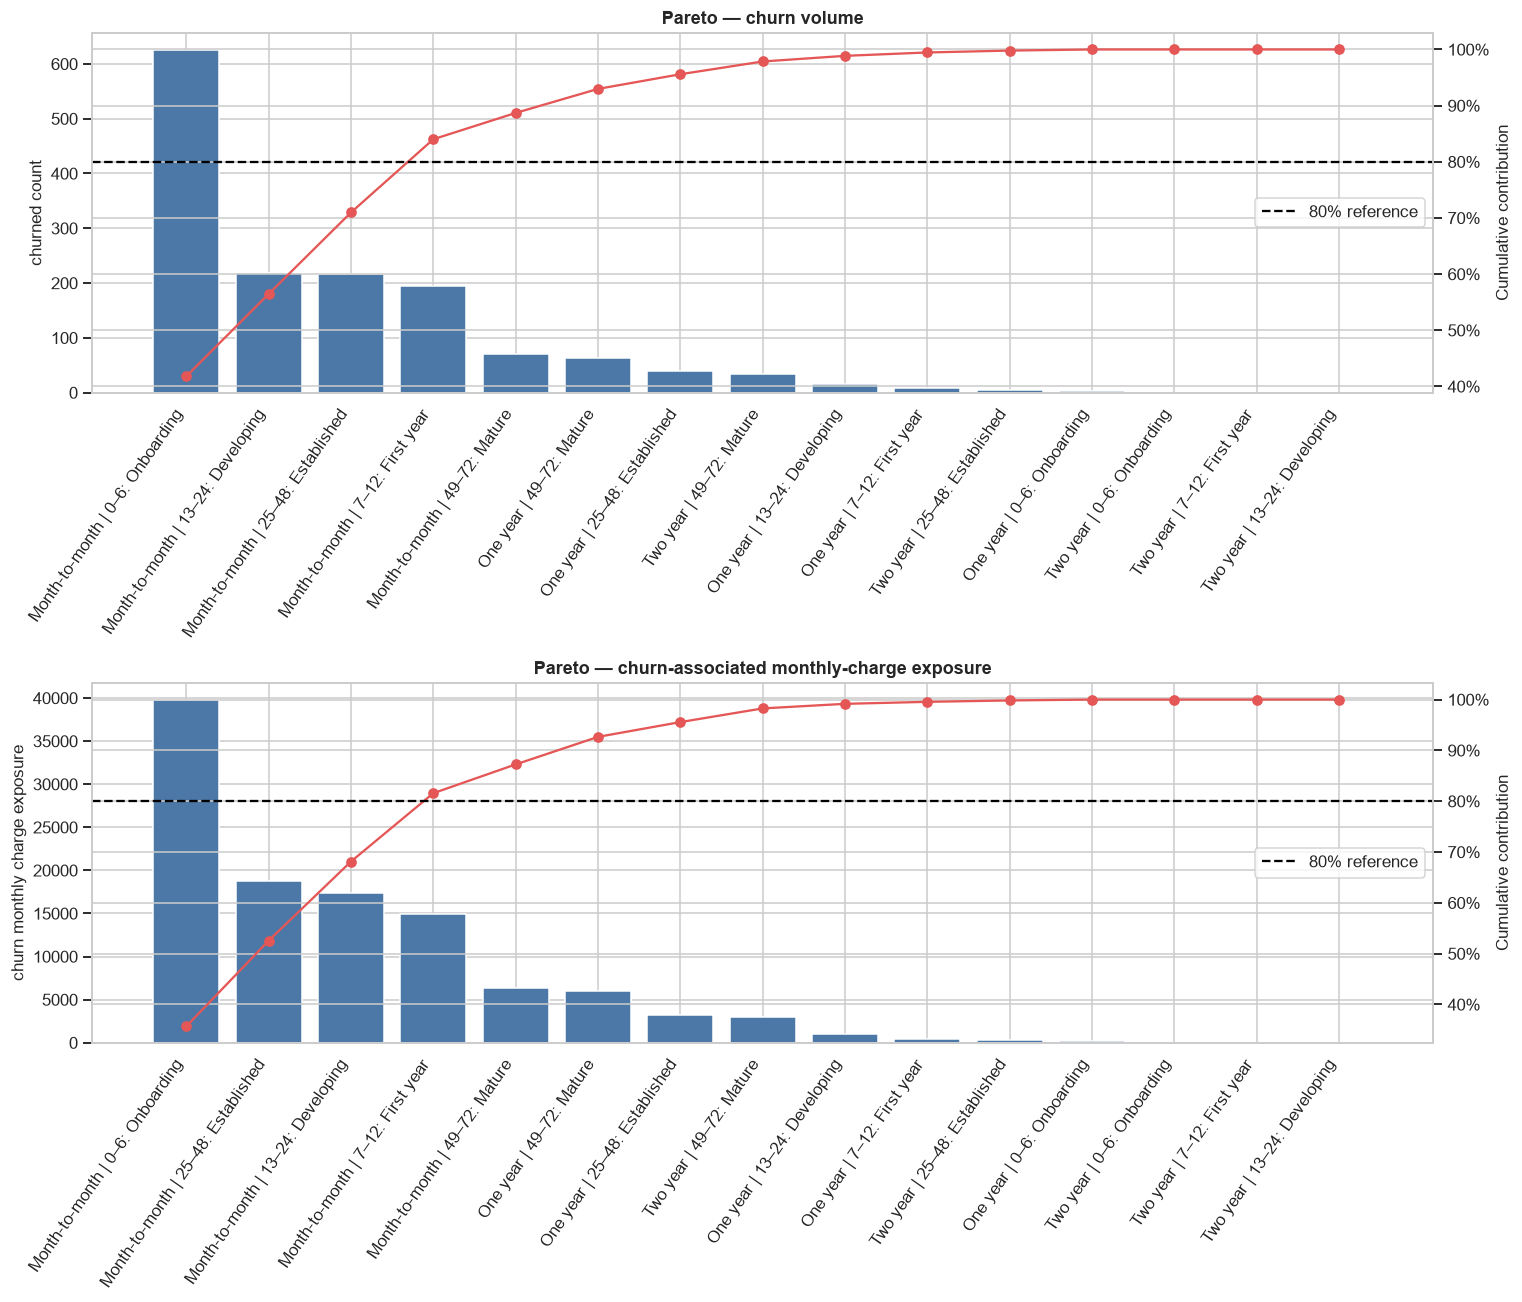

In [9]:
# ruff: noqa: E501
def pareto_table(table: pd.DataFrame, metric: str) -> pd.DataFrame:
    # Rank mutually exclusive segments and compute cumulative contribution.
    ranked = table.sort_values(metric, ascending=False).copy()
    ranked["segment_label"] = (
        ranked["Contract"].astype(str) + " | " + ranked["tenure_segment"].astype(str)
    )
    ranked["cumulative_contribution"] = ranked[metric].cumsum() / ranked[metric].sum()
    ranked["cumulative_segment_share"] = (np.arange(len(ranked)) + 1) / len(ranked)
    return ranked


churn_pareto = pareto_table(risk_value, "churned_count")
exposure_pareto = pareto_table(risk_value, "churn_monthly_charge_exposure")
display(
    churn_pareto[
        [
            "segment_label",
            "customer_count",
            "churned_count",
            "cumulative_contribution",
            "cumulative_segment_share",
        ]
    ]
)
display(
    exposure_pareto[
        [
            "segment_label",
            "customer_count",
            "churn_monthly_charge_exposure",
            "cumulative_contribution",
            "cumulative_segment_share",
        ]
    ]
)

fig, axes = plt.subplots(2, 1, figsize=(14, 12))
for axis, table, metric, title in [
    (axes[0], churn_pareto, "churned_count", "Pareto — churn volume"),
    (
        axes[1],
        exposure_pareto,
        "churn_monthly_charge_exposure",
        "Pareto — churn-associated monthly-charge exposure",
    ),
]:
    positions = np.arange(len(table))
    axis.bar(positions, table[metric], color="#4C78A8")
    axis.set_xticks(positions, table["segment_label"], rotation=55, ha="right")
    axis.set_ylabel(metric.replace("_", " "))
    axis.set_title(title)
    cumulative_axis = axis.twinx()
    cumulative_axis.plot(
        positions, table["cumulative_contribution"], color="#E45756", marker="o"
    )
    cumulative_axis.axhline(0.80, color="black", linestyle="--", label="80% reference")
    cumulative_axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
    cumulative_axis.set_ylabel("Cumulative contribution")
    cumulative_axis.legend(loc="center right")
fig.tight_layout()
plt.show()

**Observed concentration finding.** The top 3 of 15 segments (20%) contribute 70.97% of
churn volume and 68.13% of exposure, so the data do not show an exact 80/20 pattern. Four
segments (26.67%) are needed to cross 80%, reaching 84.01% of churn and 81.58% of exposure.
All four are month-to-month lifecycle groups; onboarding ranks first with 625 churners and
39,732.45 exposure. Concentration can focus investigation, but addressability and treatment
benefit remain unknown.

# 9. Churn-rate lift analysis

$$Lift_s=\frac{P(Churn=Yes\mid Segment=s)}{P(Churn=Yes)}.$$

Lift above one means a segment's observed rate exceeds the development baseline; one means
equal; below one means lower. Lift is relative, has no direct revenue unit, and can be
unstable in small groups. It is neither causal uplift nor an individual probability.

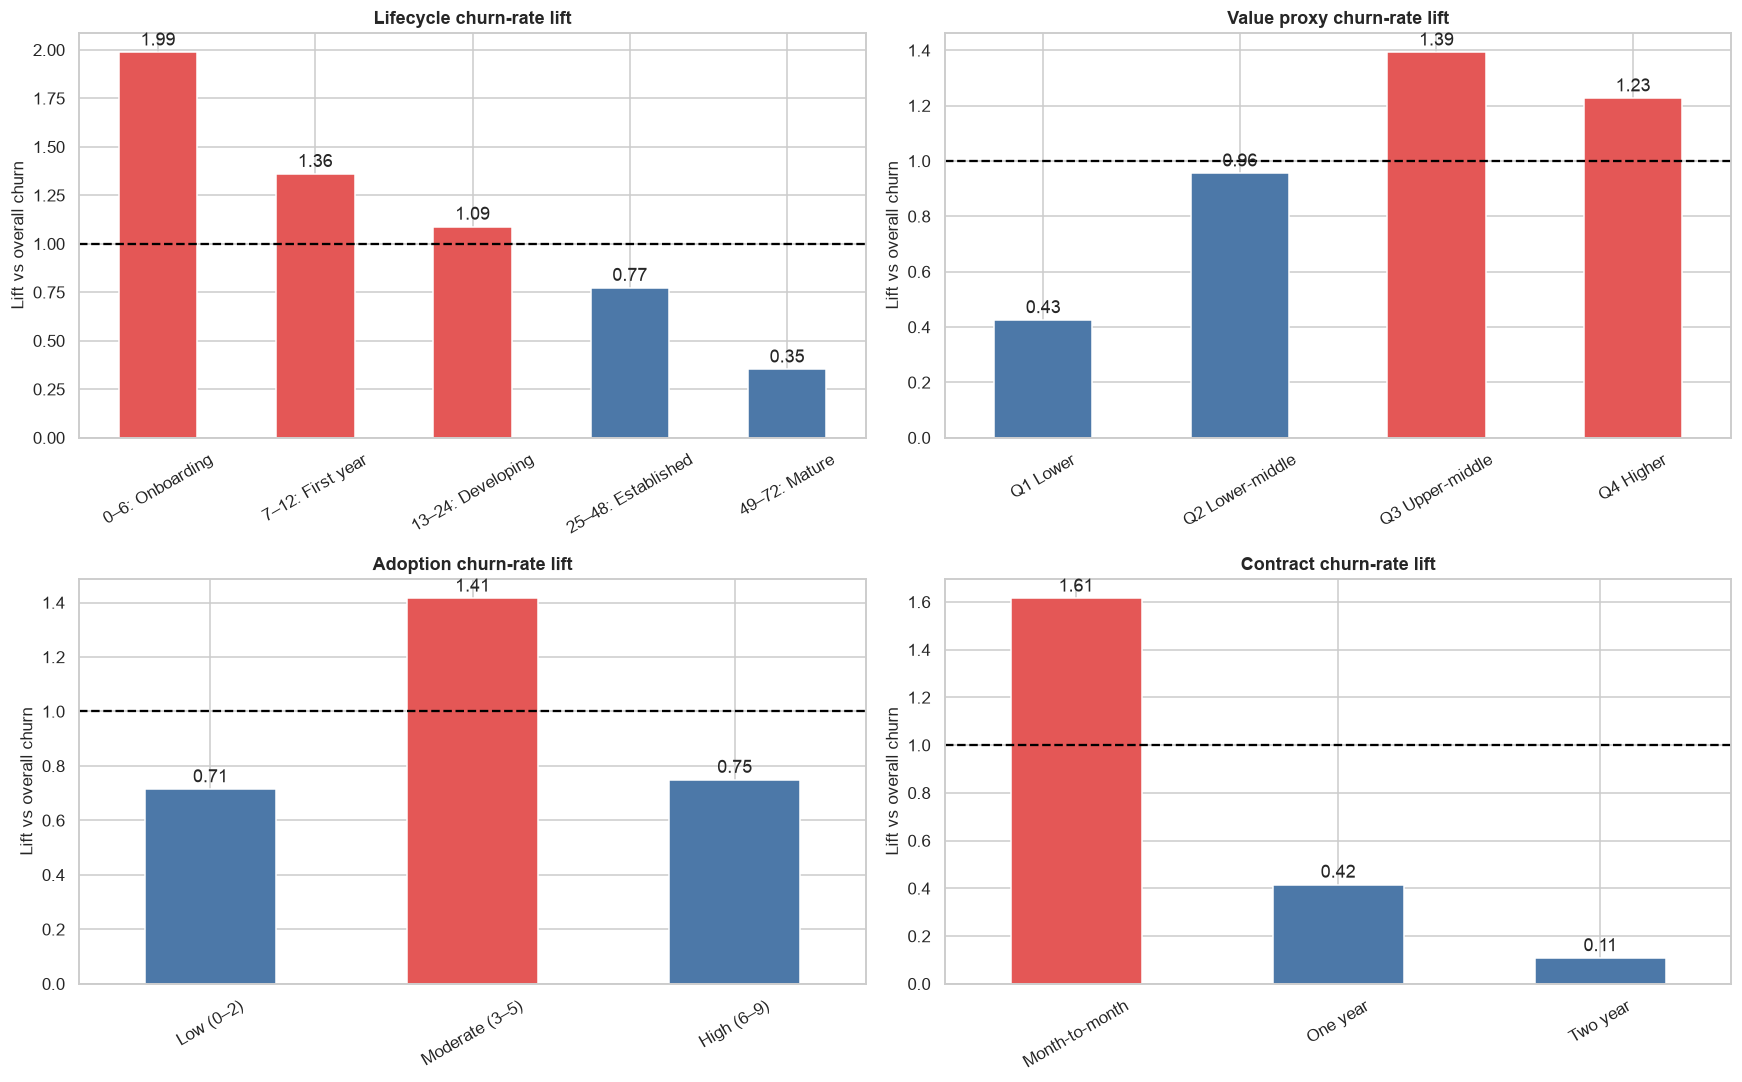

In [10]:
# ruff: noqa: E501
lift_views = {
    "Lifecycle": lifecycle_summary["churn_rate_lift"],
    "Value proxy": value_summary["churn_rate_lift"],
    "Adoption": adoption_summary["churn_rate_lift"],
    "Contract": contract_summary["churn_rate_lift"],
}
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for axis, (title, values) in zip(axes.flat, lift_views.items(), strict=True):
    colors = ["#E45756" if value > 1 else "#4C78A8" for value in values]
    values.plot.bar(ax=axis, color=colors)
    axis.axhline(1, color="black", linestyle="--")
    axis.set(
        title=f"{title} churn-rate lift", xlabel="", ylabel="Lift vs overall churn"
    )
    axis.tick_params(axis="x", rotation=30)
    axis.bar_label(axis.containers[0], fmt="%.2f", padding=2)
fig.tight_layout()
plt.show()

**Observed lift finding.** Onboarding lift is 1.99; Q3 value is 1.39 and Q4 is 1.23;
moderate adoption is 1.41; month-to-month contract is 1.61. Mature lifecycle (0.35), high
adoption (0.75), one-year (0.42), and two-year contracts (0.11) are below baseline. The
largest descriptive lifts align with prior EDA but do not prove intervention effects.

# 10. Retention prioritization and business recommendations

An evidence-based preliminary investigation order is:

1. **Month-to-month onboarding:** highest churn volume and exposure concentration; examine
   acquisition promises, installation, first bills, early service friction, and eligibility
   for retention contact.
2. **Month-to-month developing/established high-value groups:** above-baseline observed
   rates with higher charge proxies; test whether offers are incremental and economically
   justified rather than assuming conversion causes retention.
3. **Internet subscribers lacking both security and support:** high observed rate and large
   volume, while recognizing self-selection and service context.
4. **Fibre and electronic-payment-related patterns:** use previous stratified findings and
   diagnose service, price, and billing experience rather than interpreting categories as
   causal levers.

Operational prioritization ultimately needs calibrated predictions, contact eligibility,
margin, cost, treatment uplift, capacity, fairness review, and controlled experiments. This
notebook supplies descriptive segment intelligence only.

# 11. Interview questions with speakable answers

### 1. Why can a segment have high churn rate but low business priority?

**Speakable answer:** “Rate is only one dimension. A tiny segment may have high churn but
little volume or value, and the churn may not be addressable. I combine rate, lift, volume,
monthly-charge exposure, sample size, intervention cost, and expected incremental benefit.
This notebook covers the descriptive pieces but not causal benefit or cost.”

### 2. Is churn-associated monthly-charge exposure lost MRR?

**Speakable answer:** “No. It sums the MonthlyCharges field for observed churners. We do
not independently know currency, exact churn timing, future billing, collections, margins,
or whether revenue is recoverable. I label it exposure and avoid claiming realized or
future recurring-revenue loss.”

### 3. Why is a risk–value quadrant not an individual churn model?

**Speakable answer:** “The quadrant uses historical rates for contract–lifecycle groups and
mean charges. Everyone in a group shares the same descriptive placement despite different
individual circumstances. A prediction model estimates conditional individual risk and
needs calibration and out-of-sample validation; treatment prioritization additionally needs
uplift and economics.”

### 4. Did the Pareto analysis prove an 80/20 rule?

**Speakable answer:** “No. The top 20% of mutually exclusive segments contribute about 71%
of churn and 68% of exposure. Four of fifteen segments, or 26.7%, are needed to exceed 80%.
The outcome is concentrated, but it is not an exact 80/20 pattern.”

# 12. Verification, leakage audit, and limitations

The final cell checks complete and mutually exclusive segments, KPI reconciliation,
minimum-sample safeguards, unchanged source bytes, and unchanged hashes for all six prior
notebooks.

In [11]:
# ruff: noqa: E501
expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
    "06_outlier_anomaly_analysis.ipynb": "f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece57da2f74d9eb3e1ef4b",
}
observed_previous_hashes = {
    name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest()
    for name in expected_previous_hashes
}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()

assert (
    analysis_df["tenure_segment"].notna().all()
    and analysis_df["value_segment"].notna().all()
)
assert (
    lifecycle_summary["customer_count"].sum()
    == value_summary["customer_count"].sum()
    == len(df)
)
assert (
    lifecycle_summary["churned_count"].sum()
    == value_summary["churned_count"].sum()
    == churned_mask.sum()
)
assert np.isclose(
    lifecycle_summary["total_monthly_charge_exposure"].sum(), total_monthly_charges
)
assert np.isclose(
    lifecycle_summary["churn_monthly_charge_exposure"].sum(), churn_monthly_exposure
)
assert (
    risk_value["customer_count"].sum() == len(df)
    and risk_value["churned_count"].sum() == churned_mask.sum()
)
assert (
    risk_value.loc[~risk_value["sample_sufficient"], "risk_value_quadrant"]
    .eq("Insufficient sample (<30)")
    .all()
)
assert analysis_df["service_count"].between(0, 9).all()
assert (
    source_sha256_before
    == source_sha256_after
    == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
)
assert (
    development_path == (PROJECT_ROOT / "data/processed/development.parquet").resolve()
)
assert observed_previous_hashes == expected_previous_hashes

print("All notebook verification checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Source development data remained byte-for-byte unchanged.")
print("Held-out test and complete validated datasets were not accessed.")
display(
    pd.DataFrame(
        {
            "expected_sha256": expected_previous_hashes,
            "observed_sha256": observed_previous_hashes,
        }
    )
)

All notebook verification checks passed.
Loaded data source: data/processed/development.parquet
Source development data remained byte-for-byte unchanged.
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...
06_outlier_anomaly_analysis.ipynb,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...


## Remaining limitations

- The dataset is a static observational snapshot with no event time, churn date, invoice
  history, verified currency, margins, acquisition/service costs, or intervention outcomes.
- MonthlyCharges and TotalCharges are exposure proxies, not profit, CLV, realized loss, or
  forecast revenue.
- Rule-based boundaries and quadrant thresholds are exploratory and sample-dependent.
- Segment rates are marginal and can reflect confounding, selection, eligibility, and
  overlapping business characteristics.
- No uncertainty intervals, significance tests, individual prediction, calibration,
  clustering, causal uplift, optimization, feature engineering, or production targeting is
  performed.